# Aprendizado Supervisionado — Classificação na prática 🍷

**Base:** Wine (UCI/sklearn) — 178 amostras, 13 atributos químicos, 3 cultivares.

**Agenda da aula:**
1. Conceitos: o que é classificação e como ela difere de regressão
2. O processo completo de um projeto de ML (e onde a maioria erra: vazamento de dados)
3. Por que EDA é obrigatório antes de qualquer modelo
4. EDA manual (pandas/matplotlib/seaborn) e automático (ydata-profiling)
5. Cross-Validation: por que um único train/test não basta
6. 25 modelos testados manualmente com busca de hiperparâmetros (incl. deep learning com PyTorch)
7. Avaliação final honesta no conjunto de teste
8. AutoML (FLAML e PyCaret) — e o que ele automatiza (e o que não)

In [1]:
# Execute uma única vez. Se preferir, rode os mesmos comandos no PowerShell
# com o venv do projeto ativado (pip install ...).
# Núcleo:
# %pip install -U numpy pandas matplotlib seaborn scikit-learn scipy ydata-profiling
# Boosting de terceiros (recomendado):
# %pip install -U lightgbm xgboost catboost
# Deep learning (escolha uma; o notebook usa PyTorch):
# %pip install -U torch
# AutoML (opcional):
# %pip install -U flaml
# %pip install -U pycaret   # pode ter suporte limitado a versões muito novas do Python

In [2]:
import sys
print(f"Python: {sys.version.split()[0]}\n")

# torch primeiro: no Windows, importar lightgbm/catboost antes dele
# pode gerar conflito de DLLs no mesmo processo
for lib in ["torch", "numpy", "pandas", "matplotlib", "seaborn", "sklearn",
            "ydata_profiling", "lightgbm", "xgboost", "catboost", "flaml", "pycaret"]:
    try:
        mod = __import__(lib)
        print(f"{lib:16s} {getattr(mod, '__version__', '?')}")
    except Exception as e:
        print(f"{lib:16s} ERRO → {type(e).__name__}: {str(e)[:80]}")                            

Python: 3.11.9

torch            2.14.1+cpu
numpy            1.26.4
pandas           2.1.4
matplotlib       3.7.5
seaborn          0.13.2
sklearn          1.4.2


C:\Users\calab\AppData\Local\Temp\ipykernel_20828\1071944575.py:9: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  mod = __import__(lib)


ydata_profiling  4.18.4
lightgbm         4.5.0
xgboost          3.2.0
catboost         1.2.10
flaml            2.7.0
pycaret          3.3.2


## 1. Aprendizado supervisionado e classificação

No aprendizado **supervisionado**, o algoritmo recebe exemplos rotulados (X, y) e aprende uma função
**f: X → y** que generalize para dados novos. Se **y** é contínuo → **regressão** (prever o preço do vinho).
Se **y** é discreto → **classificação** (prever a cultivar). Aqui: 13 atributos químicos → 1 de 3 classes.

### Vocabulário essencial
- **Features (X):** os atributos de cada instância (teor de álcool, flavanoides, proline...).
- **Alvo (y):** o rótulo que queremos prever.
- **Classificação binária / multiclasse / multilabel:** 2 classes / N classes mutuamente exclusivas /
  várias classes simultâneas (ex.: um filme pode ser "ação" **e** "comédia").
- **Hard vs soft:** prever só a classe ("class_1") vs prever **probabilidades** por classe
  (0.72 / 0.21 / 0.07). Probabilidades permitem thresholds, ranqueamento e análise de custo.
- **Modelos discriminativos** aprendem a fronteira entre classes (SVM, logística, redes).
  **Modelos generativos** aprendem como cada classe "é" e aplicam Bayes (Naive Bayes, LDA).

### O dilema central: overfitting vs underfitting
- **Overfitting:** o modelo decora o treino (memoriza ruído) e falha em dados novos.
- **Underfitting:** o modelo é simples demais e erra até no treino.
- A **variância** cresce com a complexidade; o **viés** cai. O objetivo é o equilíbrio —
  e é por isso que existem hiperparâmetros (profundidade da árvore, C do SVM, dropout da rede...).

**Pergunta para a turma:** se o modelo acerta 100% no treino e 70% no teste, o problema é viés ou variância?

## 2. O processo de um projeto de classificação

1. **Entender o problema e definir a métrica** (acurácia serve? ou recall importa mais?)
2. **Coletar os dados** (CSV, banco, API)
3. **EDA** — explorar, limpar, entender. *Nunca* pule esta etapa.
4. **Preparação:** encoding, escala, imputação, seleção de features
5. **Split treino/teste** — o teste fica "trancado" até o fim
6. **Baseline** (DummyClassifier) — o mínimo que qualquer modelo precisa vencer
7. **Seleção de modelo + tuning via cross-validation** (SÓ no treino)
8. **Avaliação final no teste** — uma única vez, sem ajustes depois
9. **Interpretação** — quais features pesam? A decisão faz sentido?
10. **Deploy e monitoramento** — o mundo muda; o modelo envelhece (data drift)

### ⚠️ Vazamento de dados (data leakage) — o erro nº 1
Toda informação "aprendida dos dados" deve vir **apenas do treino**:
- Escalar (StandardScaler) usando média/desvio de TODOS os dados antes do split → vazamento.
- Selecionar features olhando o teste → vazamento.
- Tunar hiperparâmetros contra o teste → o teste deixa de medir generalização.

**Solução estrutural:** encapsular transformações + modelo em um `Pipeline` — o sklearn
aprende cada transformação **dentro de cada fold** da validação cruzada, automaticamente.

## 3. Cross-Validation: por que um único train/test não basta

Com bases pequenas (178 linhas!), a nota do modelo em **um único** split depende da "sorte"
da divisão: um fold bom aqui, um fold ruim ali. A **validação cruzada k-fold** resolve isso:

1. Divide o treino em **k partições** (folds);
2. Treina **k vezes**: em cada rodada, 1 fold vira validação e os outros k−1 viram treino;
3. A nota final = **média ± desvio** dos k folds → estimativa de generalização com incerteza.

### Variantes que você precisa conhecer
- **StratifiedKFold:** mantém a proporção das classes em cada fold. **Padrão em classificação**
  (imagine um fold sem nenhuma amostra da classe minoritária...).
- **RepeatedKFold:** repete o k-fold com shuffles diferentes → média ainda mais estável.
- **LOOCV:** k = n (cada amostra vira teste 1×). Sem viés, porém caríssimo.
- **GroupKFold:** folds por *grupo* (ex.: todas as medições de um mesmo paciente num único fold) —
  evita que o modelo "reconheça" o grupo.
- **TimeSeriesSplit:** dados temporais — treino sempre no passado, validação no futuro.

### Nested CV (a forma honesta de tunar hiperparâmetros)
GridSearchCV com CV **interna** escolhe os hiperparâmetros; uma CV **externa** mede a
generalização dessa escolha. Tunar e reportar na mesma CV gera estimativa **otimista**.

### Regra de ouro
Pipeline dentro do cross_validate → nenhuma transformação "espiando" o fold de validação.
E o conjunto de teste? **Sai da gaveta 1×, no final, para o relatório.**

## 4. Métricas: qual número olhar?

Da matriz de confusão nascem as métricas:
- **Acurácia:** acertos/total. Traiçoeira com desbalanceamento (99% de "não fraude" → prever tudo "não" dá 99%).
- **Precision (PPV):** dos que o modelo disse "positivo", quantos eram mesmo?
  Alto quando o **custo do falso positivo** é alto (bloquear cartão, acusar inocente).
- **Recall (sensibilidade):** dos positivos reais, quantos foram encontrados?
  Alto quando o **custo do falso negativo** é alto (diagnóstico, fraude).
- **F1:** harmônica entre precision e recall — pune desequilíbrio entre os dois.
- **Especificidade / FPR:** a outra ponta da matriz.
- **ROC-AUC:** qualidade do **ranqueamento** das probabilidades, independente de threshold.
  Em multiclasse: estratégia OvR (uma classe vs o resto) ou OvO, média macro.
- **Log-loss:** pega erros *confiantes* — uma probabilidade errada com 99% de certeza dói muito mais.

### Multiclasse: como agregar?
- **macro:** média simples por classe → trata classes igualmente (o que queremos aqui);
- **weighted:** pondera pelo tamanho da classe (nobreza com desbalanceamento forte);
- **micro:** agrega contagens globais (≈ acurácia em classificação single-label).

**Nossa escolha:** **F1-macro** na CV — a Wine tem leve desbalanceamento (59/71/48) e
nenhuma classe "importa mais" que outra. Em problema real, a métrica nasce do **custo de negócio**.

## 5. Parâmetros × hiperparâmetros

- **Parâmetros:** o modelo *aprende* (coeficientes da logística, pesos da rede, splits da árvore).
- **Hiperparâmetros:** *nós* definimos antes do treino (nº de vizinhos do KNN, C do SVM,
  profundidade da árvore, taxa de aprendizado, nº de épocas, dropout).

Como escolhê-los? **Busca com CV:**
- **GridSearchCV:** testa todas as combinações da grade. Exaustivo e caro, mas completo.
- **RandomizedSearchCV:** sorteia N combinações de distribuições. Com o mesmo orçamento,
  explora **mais valores distintos** — quase sempre a melhor razão custo/benefício.
- **Busca bayesiana:** modela "quais regiões da grade prometem" e explora de forma inteligente
  (é o que os AutoMLs usam por baixo dos panos).

⚠️ A busca **sempre** usa CV no treino — nunca no teste (lembre da CV aninhada).

## 6. EDA: olhar antes de modelar

Modelar sem EDA é receitar antes de examinar. O EDA responde:
1. **Qualidade:** há nulos? duplicatas? outliers? erros de digitação em categorias?
2. **Tipos e distribuições:** cada feature é contínua, contagem, ordinal? Há assimetria
   (p.ex. *proline*) que peça transformação log?
3. **Balanceamento do alvo:** 59/71/48 → precisa de estratificação e métrica macro.
4. **Correlações:** *flavanoids* e *total_phenols* têm ρ ≈ 0.86 — multicolinearidade
   perturba modelos lineares (logística, LDA, NB) e infla importância "redundante".
5. **Escala:** KNN, SVM, redes e PCA dependem de distância/escala → padronização;
   árvores e boosting são indiferentes.
6. **Separação visível:** pairplots já sugerem que o problema é "fácil" — o que calibra
   a expectativa de acurácia e evita superengenharia.

**Papel do EDA automático (ydata-profiling):** gera em segundos um relatório completo
(distribuições, interações, correlações, nulos, alertas). É **ponto de partida** para a
conversa, não ponto final — automação não substitui o olhar crítico de quem conhece o domínio.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

from sklearn.datasets import load_wine
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [4]:
wine = load_wine()

In [5]:
wine

{'data': array([[1.423e+01, 1.710e+00, 2.430e+00, ..., 1.040e+00, 3.920e+00,
         1.065e+03],
        [1.320e+01, 1.780e+00, 2.140e+00, ..., 1.050e+00, 3.400e+00,
         1.050e+03],
        [1.316e+01, 2.360e+00, 2.670e+00, ..., 1.030e+00, 3.170e+00,
         1.185e+03],
        ...,
        [1.327e+01, 4.280e+00, 2.260e+00, ..., 5.900e-01, 1.560e+00,
         8.350e+02],
        [1.317e+01, 2.590e+00, 2.370e+00, ..., 6.000e-01, 1.620e+00,
         8.400e+02],
        [1.413e+01, 4.100e+00, 2.740e+00, ..., 6.100e-01, 1.600e+00,
         5.600e+02]]),
 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1

In [6]:
df = pd.DataFrame(wine.data, columns=wine.feature_names)
df["target"] = wine.target
df["target_name"] = df["target"].map(dict(enumerate(wine.target_names)))

# Em aulas/produção, os dados raramente "nascem" no sklearn: normalmente chegam por CSV,
# banco ou API. Simulamos isso — grava e relê o CSV (aqui entra, num projeto real, a limpeza).

In [7]:
df

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,target_name
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0,2,class_2
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0,2,class_2
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0,2,class_2
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0,2,class_2


In [8]:
df.to_csv(r"..\datasets\wine.csv", index=False)
df = pd.read_csv("..\datasets\wine.csv")
print(df.info())
print(df.shape)
print(df.head())
print(df.tail())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

In [9]:
display(df.describe().T.round(2))
print("Nulos totais:", df.isna().sum().sum())
print("Linhas duplicadas:", df.duplicated().sum())

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


Nulos totais: 0
Linhas duplicadas: 0


In [10]:
ax = df["target_name"].value_counts().reindex(wine.target_names).plot(
    kind="bar", color=["#4C72B0", "#55A868", "#C44E52"], figsize=(6, 4))
ax.bar_label(ax.containers[0])
ax.set(title="Distribuição das classes",
       xlabel="Cultivar", ylabel="nº de amostras")
plt.tight_layout()
plt.show()

<Figure size 600x400 with 1 Axes>

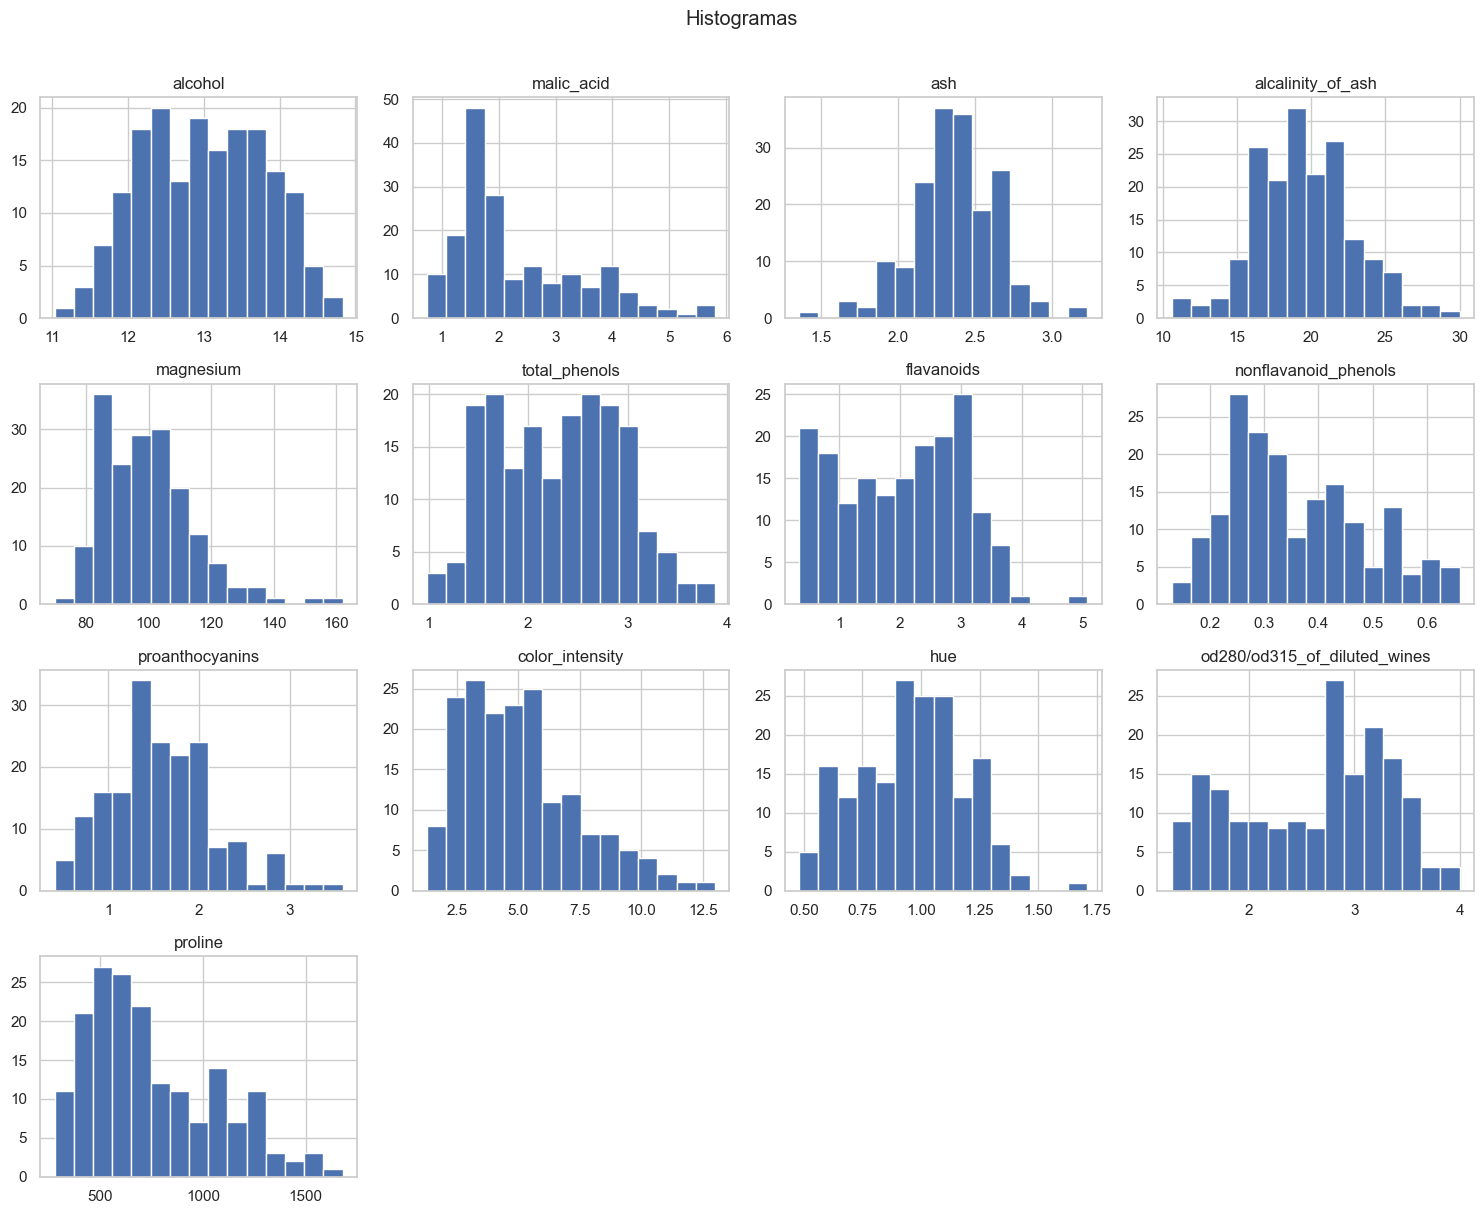

In [11]:
df[wine.feature_names].hist(bins=15, figsize=(15, 12), color="#4C72B0", edgecolor="white")
plt.suptitle("Histogramas", y=1.01)
plt.tight_layout()
plt.show()

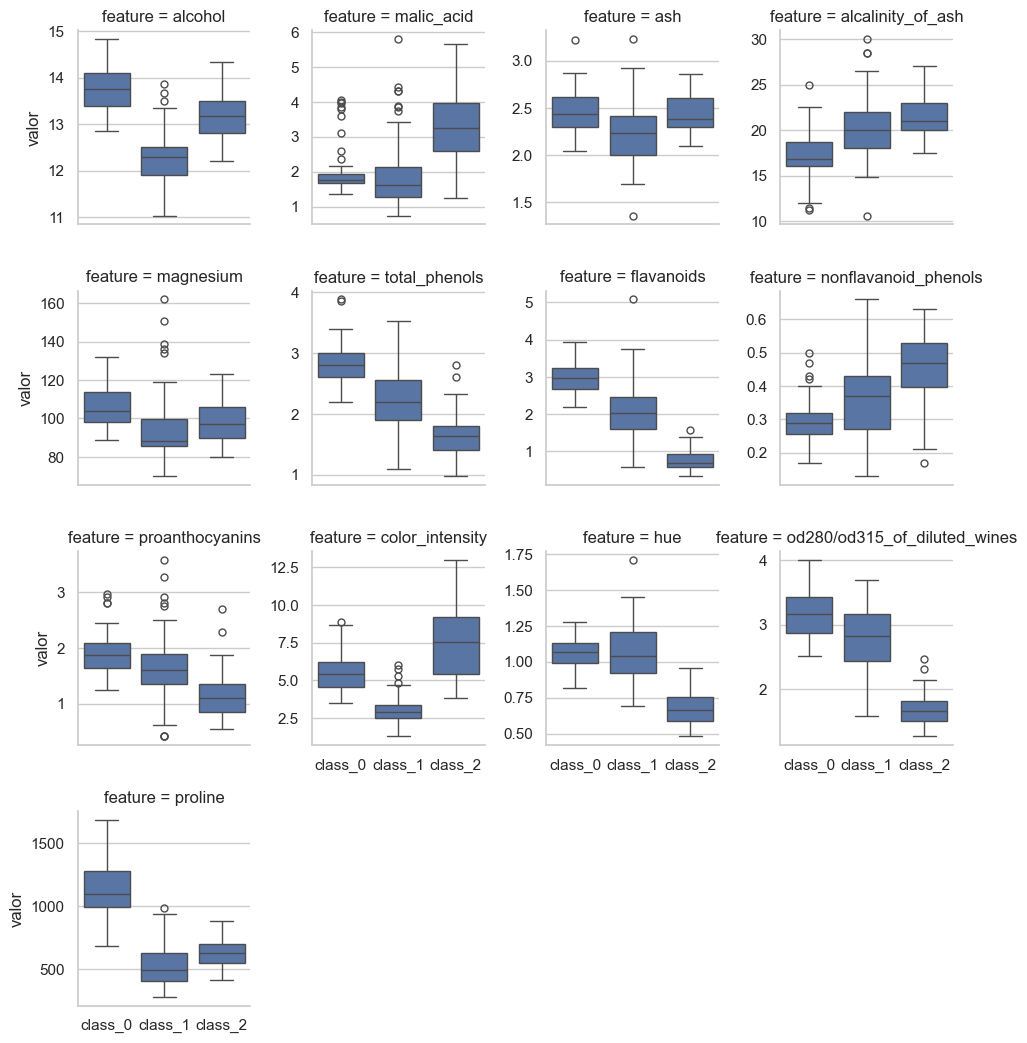

In [12]:
df_melt = df.melt(id_vars="target_name", value_vars=wine.feature_names,
                  var_name="feature", value_name="valor")
g = sns.catplot(data=df_melt, x="target_name", y="valor", col="feature", col_wrap=4,
                kind="box", sharey=False, height=2.7, aspect=0.9)
g.set_xlabels("")
plt.show()
# Leitura: features cujas caixas quase não se sobrepõem (flavanoids, proline,
# od280/od315) são discriminantes fortes; as que se sobrepõem (ash) são fracas.


Pares mais correlacionados:
 total_phenols  flavanoids                      0.86
flavanoids     od280/od315_of_diluted_wines    0.79
total_phenols  od280/od315_of_diluted_wines    0.70
flavanoids     proanthocyanins                 0.65
alcohol        proline                         0.64
total_phenols  proanthocyanins                 0.61
dtype: float64


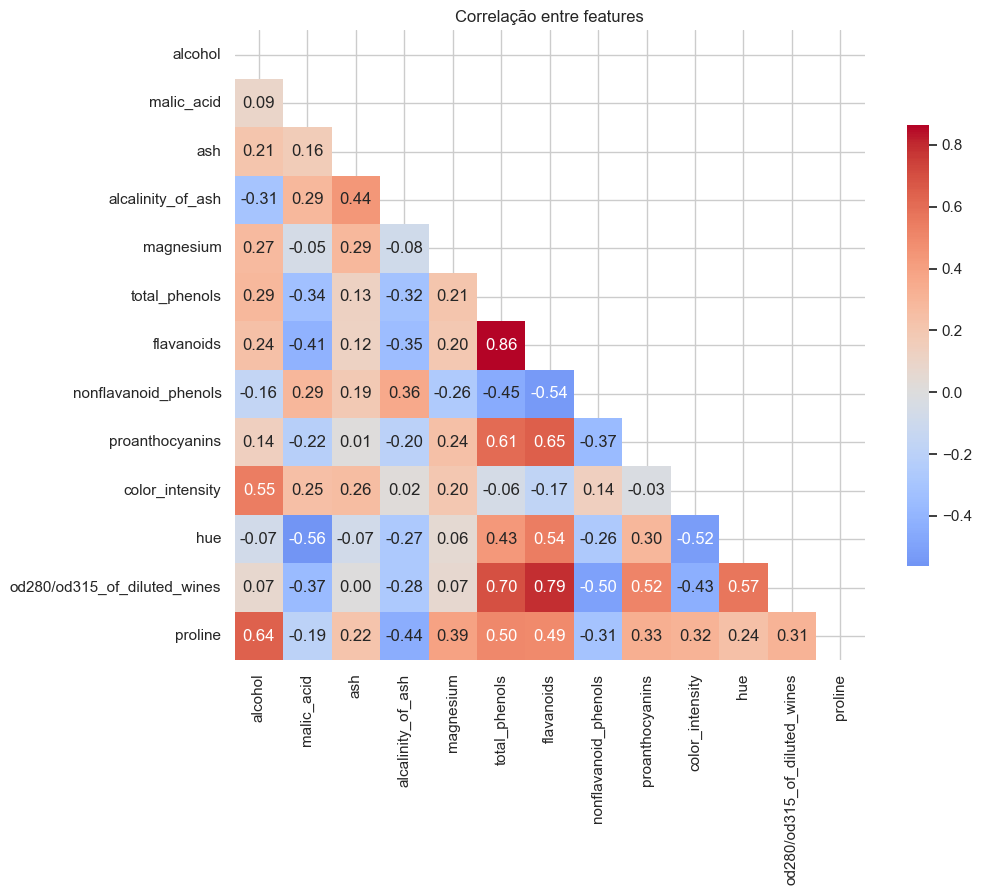

In [13]:
corr = df[wine.feature_names].corr()

plt.figure(figsize=(11, 9))
mascara = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True, cbar_kws={"shrink": 0.7})
plt.title("Correlação entre features")
plt.tight_layout()

pares = (corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1))
             .stack().sort_values(key=abs, ascending=False).head(6))
print("\nPares mais correlacionados:\n", pares.round(2))
# total_phenols × flavanoids (ρ≈0.86): redundância — relevante p/ modelos lineares.

F-statistic (quanto maior, mais discriminante):
 flavanoids                      233.9
proline                         207.9
od280/od315_of_diluted_wines    190.0
alcohol                         135.1
color_intensity                 120.7
hue                             101.3
total_phenols                    93.7
malic_acid                       36.9
alcalinity_of_ash                35.8
proanthocyanins                  30.3
nonflavanoid_phenols             27.6
ash                              13.3
magnesium                        12.4
dtype: float64


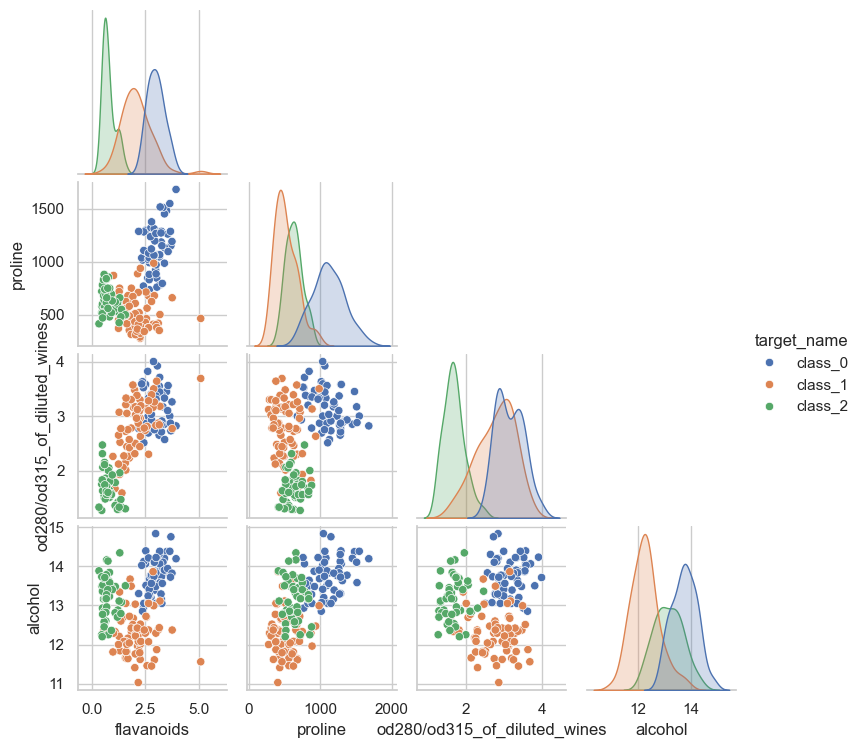

In [14]:
from sklearn.feature_selection import f_classif

# ⚠️ Aqui usamos TODOS os dados só para EDA/didática. Seleção de features "de verdade"
# deve acontecer dentro do pipeline, durante a CV — caso contrário, vazamento.
F, p = f_classif(df[wine.feature_names], df["target"])
relevancia = pd.Series(F, index=wine.feature_names).sort_values(ascending=False)
print("F-statistic (quanto maior, mais discriminante):\n", relevancia.round(1))

top4 = relevancia.head(4).index.tolist()
sns.pairplot(df, vars=top4, hue="target_name", corner=True,
             height=1.9, diag_kind="kde", palette="deep")
plt.show()

In [15]:
# Outliers pela regra de Tukey (IQR)
print("Outliers (IQR 1.5×) por feature:")
for col in wine.feature_names:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    if n_out:
        print(f"  {col:30s} {n_out}")

print("\nAssimetria (skew):")
print(df[wine.feature_names].skew().sort_values(ascending=False).head(5).round(2))

display(df.groupby("target_name")[wine.feature_names].mean().T.round(2))
# proline: classe_0 ≈ 1075 vs classe_1 ≈ 678 vs classe_2 ≈ 500 → separador claro.

Outliers (IQR 1.5×) por feature:
  malic_acid                     3
  ash                            3
  alcalinity_of_ash              4
  magnesium                      4
  proanthocyanins                2
  color_intensity                4
  hue                            1

Assimetria (skew):
magnesium          1.10
malic_acid         1.04
color_intensity    0.87
proline            0.77
proanthocyanins    0.52
dtype: float64


target_name,class_0,class_1,class_2
alcohol,13.74,12.28,13.15
malic_acid,2.01,1.93,3.33
ash,2.46,2.24,2.44
alcalinity_of_ash,17.04,20.24,21.42
magnesium,106.34,94.55,99.31
total_phenols,2.84,2.26,1.68
flavanoids,2.98,2.08,0.78
nonflavanoid_phenols,0.29,0.36,0.45
proanthocyanins,1.90,1.63,1.15
color_intensity,5.53,3.09,7.40


## 7. EDA automático — ydata-profiling

O pacote se chama **`ydata-profiling`** (antigo `pandas-profiling`). Em uma linha ele produz:
estatísticas por variável, histogramas, interações 2 a 2, correlações, nulos, duplicatas e **alertas**.
Use como **rascunho inicial** do EDA e leve as hipóteses para a exploração manual (Parte 3).

Em bases grandes, use `minimal=True` para acelerar. O relatório sai em HTML — ótimo para compartilhar.

In [16]:
try:
    from ydata_profiling import ProfileReport
    perfil = ProfileReport(df, title="Wine — EDA automático (ydata-profiling)",
                           explorative=True)
    perfil.to_notebook_iframe()          # renderiza aqui no notebook
    perfil.to_file("../outputs/wine_eda_report.html")  # salva para compartilhar
except ImportError:
    print("ydata-profiling não instalado. Instale com: %pip install ydata-profiling")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 15/15 [00:00<?, ?it/s][A


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

## 8. Split e Pipeline: a arquitetura anti-vazamento

- `train_test_split(stratify=y)` mantém 59/71/48 nos dois lados; `random_state=42` garante reprodutibilidade.
- Toda modelagem (inclusive a escala!) será empacotada em `Pipeline(StandardScaler(), modelo)`.
  Na CV, o sklearn treina o scaler **só com os folds de treino** e aplica no fold de validação —
  zero vazamento, sem esforço manual.
- Árvores/boosting não exigem escala, mas não sofrem com ela — usamos pipeline uniforme para simplificar a aula.

In [17]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["target", "target_name"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(f"Treino: {X_train.shape} | Teste: {X_test.shape}")
print("Proporções no treino:", np.bincount(y_train) / len(y_train))
print("Proporções no teste :", np.bincount(y_test) / len(y_test))

Treino: (142, 13) | Teste: (36, 13)
Proporções no treino: [0.33098592 0.40140845 0.26760563]
Proporções no teste : [0.33333333 0.38888889 0.27777778]


In [18]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

linhas = []
for fold, (_, idx_teste) in enumerate(cv.split(X_train, y_train), start=1):
    classes, contagens = np.unique(y_train.iloc[idx_teste], return_counts=True)
    for c, n in zip(classes, contagens):
        linhas.append({"fold": f"Fold {fold}", "classe": wine.target_names[c], "n_no_teste": n})

tabela_folds = pd.DataFrame(linhas).pivot(index="fold", columns="classe", values="n_no_teste")
tabela_folds["total"] = tabela_folds.sum(axis=1)
tabela_folds
# Cada amostra é "teste" em exatamente 1 dos 5 folds → todos os dados participam da avaliação,
# e as proporções de classe se mantêm em todos os folds (por isso "stratified").

classe,class_0,class_1,class_2,total
fold,,,,
Fold 1,10,12,7,29
Fold 2,10,12,7,29
Fold 3,9,11,8,28
Fold 4,9,11,8,28
Fold 5,9,11,8,28


In [19]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

pipe_demo = Pipeline([("scaler", StandardScaler()),
                      ("modelo", LogisticRegression(max_iter=5000))])

res = cross_validate(pipe_demo, X_train, y_train, cv=cv,
                     scoring=["accuracy", "f1_macro", "balanced_accuracy"],
                     return_train_score=True)
display(pd.DataFrame(res).round(3))
# Repare: train_score ≈ test_score aqui → modelo bem calibrado para a base.
# Gap grande (train 1.00 / test 0.85) seria a assinatura do overfitting.

,fit_time,score_time,test_accuracy,train_accuracy,test_f1_macro,train_f1_macro,test_balanced_accuracy,train_balanced_accuracy
0,0.011,0.008,0.931,1.0,0.932,1.0,0.944,1.0
1,0.009,0.007,1.000,1.0,1.000,1.0,1.000,1.0
2,0.012,0.005,1.000,1.0,1.000,1.0,1.000,1.0
3,0.008,0.010,1.000,1.0,1.000,1.0,1.000,1.0
4,0.007,0.006,0.964,1.0,0.967,1.0,0.970,1.0


In [20]:
# GridSearchCV interno escolhe hiperparâmetros; a CV EXTERNA mede o que essa escolha
# vale em dados que o processo de seleção nunca viu. Sem isso, a estimativa fica otimista.
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier

cv_externa = StratifiedKFold(5, shuffle=True, random_state=1)
cv_interna = StratifiedKFold(3, shuffle=True, random_state=2)

busca = GridSearchCV(
    RandomForestClassifier(random_state=42),
    {"n_estimators": [100, 300], "max_depth": [None, 10]},
    cv=cv_interna, scoring="f1_macro", n_jobs=-1)

scores_externos = cross_val_score(busca, X_train, y_train, cv=cv_externa, scoring="f1_macro")
print("F1-macro por fold externo:", scores_externos.round(3))
print(f"Estimativa honesta de generalização: {scores_externos.mean():.3f} ± {scores_externos.std():.3f}")

F1-macro por fold externo: [0.963 0.97  0.965 1.    0.965]
Estimativa honesta de generalização: 0.972 ± 0.014


## 9. Arena de modelos: 25 candidatos, 4 famílias

| Família | Modelos |
|---|---|
| **Lineares / margens** | Regressão Logística, Ridge, SGD, Perceptron, SVC (linear, rbf, poly, sigmoid), LDA, QDA |
| **Probabilísticos / instâncias** | GaussianNB, ComplementNB (Min-Max!), KNN, Centróides |
| **Árvores e ensembles** | Árvore, Random Forest, Extra Trees, Bagging, AdaBoost, Gradient Boosting, HistGradientBoosting, LightGBM, XGBoost, CatBoost |
| **Outros / redes** | Processo Gaussiano, MLP (sklearn), **MLP raso (PyTorch)**, **MLP profundo c/ dropout (PyTorch)**, Dummy (baseline) |

Cada modelo entra num `GridSearchCV` com sua **grade de hiperparâmetros** e a CV estratificada
de 5 folds, otimizando **F1-macro**. `error_score=np.nan` faz a arena não quebrar se um
candidato falhar — vida real: alguns modelos não se dão bem com certos dados.

In [21]:
# A graça da aula: um modelo de deep learning que se comporta como qualquer estimador
# do sklearn (fit/predict/proba). É isso que a API exige para entrar no GridSearchCV.
import torch
import torch.nn as nn
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.validation import check_X_y, check_array
from sklearn.preprocessing import LabelEncoder


class TorchMLP(BaseEstimator, ClassifierMixin):
    """MLP em PyTorch compatível com a API do scikit-learn."""

    def __init__(self, hidden=(64, 32), dropout=0.3, lr=1e-3, epochs=200,
                 batch_size=16, weight_decay=1e-4, seed=42):
        # TODOS os hiperparâmetros vão para self.* com o MESMO nome → o sklearn
        # consegue clonar e tunar este modelo como qualquer outro.
        self.hidden = hidden
        self.dropout = dropout
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size
        self.weight_decay = weight_decay
        self.seed = seed

    def _build(self, n_in, n_out):
        camadas, d = [], n_in
        for h in self.hidden:
            camadas += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(self.dropout)]
            d = h
        camadas.append(nn.Linear(d, n_out))
        return nn.Sequential(*camadas)

    def fit(self, X, y):
        X, y = check_X_y(X, y)
        self.le_ = LabelEncoder().fit(y)
        y_enc = self.le_.transform(y)
        self.classes_ = self.le_.classes_                       # exigência da API

        torch.manual_seed(self.seed)
        self.model_ = self._build(X.shape[1], len(self.classes_))

        X_t = torch.tensor(X, dtype=torch.float32)
        ds = torch.utils.data.TensorDataset(X_t, torch.tensor(y_enc, dtype=torch.long))
        dl = torch.utils.data.DataLoader(ds, batch_size=self.batch_size, shuffle=True)

        otimizador = torch.optim.Adam(self.model_.parameters(),
                                      lr=self.lr, weight_decay=self.weight_decay)
        perda = nn.CrossEntropyLoss()          # padrão-ouro da classificação multiclasse

        self.model_.train()
        for _ in range(self.epochs):           # 1 época = 1 passada completa pelo treino
            for xb, yb in dl:
                otimizador.zero_grad()
                loss = perda(self.model_(xb), yb)
                loss.backward()
                otimizador.step()
        return self

    def predict_proba(self, X):
        check_array(X)
        self.model_.eval()                     # desliga dropout/inference tricks
        with torch.no_grad():
            logits = self.model_(torch.tensor(np.asarray(X, dtype=np.float32)))
            return torch.softmax(logits, dim=1).numpy()

    def predict(self, X):
        return self.le_.inverse_transform(np.argmax(self.predict_proba(X), axis=1))

print("TorchMLP pronto — works como um estimador sklearn:", 
      TorchMLP().get_params())

TorchMLP pronto — works como um estimador sklearn: {'batch_size': 16, 'dropout': 0.3, 'epochs': 200, 'hidden': (64, 32), 'lr': 0.001, 'seed': 42, 'weight_decay': 0.0001}


In [22]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import (LogisticRegression, RidgeClassifier,
                                  SGDClassifier, Perceptron)
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.naive_bayes import GaussianNB, ComplementNB
from sklearn.discriminant_analysis import (LinearDiscriminantAnalysis,
                                           QuadraticDiscriminantAnalysis)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              BaggingClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier)
from sklearn.svm import SVC
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler
MODELOS = {}

MODELOS["00_Dummy (baseline)"] = {
    "estimador": DummyClassifier(strategy="most_frequent"), "grid": {}}

MODELOS["01_Regressão Logística"] = {
    "estimador": LogisticRegression(max_iter=5000, random_state=42),
    "grid": {"modelo__C": [0.01, 0.1, 1, 10, 100]}}

MODELOS["02_KNN"] = {
    "estimador": KNeighborsClassifier(),
    "grid": {"modelo__n_neighbors": [3, 5, 7, 9, 11, 13],
             "modelo__weights": ["uniform", "distance"]}}

MODELOS["03_GaussianNB"] = {
    "estimador": GaussianNB(),
    "grid": {"modelo__var_smoothing": [1e-10, 1e-9, 1e-8, 1e-7]}}

# ComplementNB exige features NÃO-negativas → pipeline interno com MinMaxScaler
MODELOS["04_ComplementNB (min-max)"] = {
    "estimador": Pipeline([("scaler", MinMaxScaler()), ("modelo", ComplementNB())]),
    "grid": {"modelo__alpha": [0.1, 0.5, 1.0, 2.0]}}

MODELOS["05_LDA"] = {
    "estimador": LinearDiscriminantAnalysis(),
    "grid": {"modelo__solver": ["lsqr", "eigen"], "modelo__shrinkage": [None, "auto"]}}

MODELOS["06_QDA"] = {
    "estimador": QuadraticDiscriminantAnalysis(),
    "grid": {"modelo__reg_param": [0.0, 0.1, 0.3, 0.5]}}

MODELOS["07_Árvore de Decisão"] = {
    "estimador": DecisionTreeClassifier(random_state=42),
    "grid": {"modelo__max_depth": [2, 3, 4, None],
             "modelo__min_samples_leaf": [1, 3, 5],
             "modelo__criterion": ["gini", "entropy"]}}

MODELOS["08_RandomForest"] = {
    "estimador": RandomForestClassifier(random_state=42, n_jobs=-1),
    "grid": {"modelo__n_estimators": [100, 300],
             "modelo__max_depth": [None, 10],
             "modelo__max_features": ["sqrt", "log2"]}}

MODELOS["09_ExtraTrees"] = {
    "estimador": ExtraTreesClassifier(random_state=42, n_jobs=-1),
    "grid": {"modelo__n_estimators": [100, 300],
             "modelo__max_depth": [None, 10],
             "modelo__max_features": ["sqrt", "log2"]}}

MODELOS["10_Bagging (DT)"] = {
    "estimador": BaggingClassifier(random_state=42, n_jobs=-1),
    "grid": {"modelo__n_estimators": [50, 100],
             "modelo__max_samples": [0.7, 1.0]}}

MODELOS["11_AdaBoost"] = {
    "estimador": AdaBoostClassifier(random_state=42),
    "grid": {"modelo__n_estimators": [50, 100, 200],
             "modelo__learning_rate": [0.1, 0.5, 1.0]}}

MODELOS["12_GradientBoosting"] = {
    "estimador": GradientBoostingClassifier(random_state=42),
    "grid": {"modelo__n_estimators": [100, 200],
             "modelo__learning_rate": [0.05, 0.1],
             "modelo__max_depth": [2, 3]}}

MODELOS["13_HistGradientBoosting"] = {
    "estimador": HistGradientBoostingClassifier(random_state=42),
    "grid": {"modelo__learning_rate": [0.05, 0.1],
             "modelo__max_iter": [100, 200],
             "modelo__max_leaf_nodes": [15, 31]}}

MODELOS["14_SVC (4 kernels)"] = {
    "estimador": SVC(random_state=42, probability=True),
    "grid": {"modelo__kernel": ["linear", "rbf", "poly", "sigmoid"],
             "modelo__C": [0.1, 1, 10]}}

MODELOS["15_SGD"] = {
    "estimador": SGDClassifier(random_state=42),
    "grid": {"modelo__loss": ["hinge", "log_loss", "modified_huber"],
             "modelo__alpha": [1e-5, 1e-4, 1e-3]}}

MODELOS["16_RidgeClassifier"] = {
    "estimador": RidgeClassifier(),
    "grid": {"modelo__alpha": [0.1, 1.0, 10.0]}}

MODELOS["17_Perceptron"] = {
    "estimador": Perceptron(random_state=42),
    "grid": {"modelo__alpha": [1e-5, 1e-4, 1e-3]}}

MODELOS["18_Processo Gaussiano"] = {
    "estimador": GaussianProcessClassifier(random_state=42),
    "grid": {}}  # RBF padrão; custo O(n³) — viável porque a base é minúscula

MODELOS["19_MLP (sklearn)"] = {
    "estimador": MLPClassifier(random_state=42, max_iter=5000, early_stopping=True),
    "grid": {"modelo__hidden_layer_sizes": [(32,), (64, 32), (100, 50)],
             "modelo__alpha": [1e-4, 1e-2],
             "modelo__learning_rate_init": [1e-3, 1e-2]}}

MODELOS["20_Centróides (shrinkage)"] = {
    "estimador": NearestCentroid(),
    "grid": {"modelo__shrink_threshold": [None, 0.1, 0.2, 0.5]}}

# ---- Terceiros (opcionais; pulados automaticamente se não instalados) ----
try:
    from lightgbm import LGBMClassifier
    MODELOS["21_LightGBM"] = {
        "estimador": LGBMClassifier(random_state=42, verbose=-1),
        "grid": {"modelo__n_estimators": [100, 300],
                 "modelo__learning_rate": [0.05, 0.1],
                 "modelo__num_leaves": [7, 15, 31]}}
except ImportError:
    print("LightGBM ausente — pulado.")

try:
    from xgboost import XGBClassifier
    MODELOS["22_XGBoost"] = {
        "estimador": XGBClassifier(random_state=42, eval_metric="logloss", verbosity=0),
        "grid": {"modelo__n_estimators": [100, 300],
                 "modelo__learning_rate": [0.05, 0.1],
                 "modelo__max_depth": [2, 3, 4]}}
except ImportError:
    print("XGBoost ausente — pulado.")

try:
    from catboost import CatBoostClassifier
    MODELOS["23_CatBoost"] = {
        "estimador": CatBoostClassifier(random_state=42, verbose=0,
                                        allow_writing_files=False),
        "grid": {"modelo__iterations": [100, 300],
                 "modelo__learning_rate": [0.05, 0.1],
                 "modelo__depth": [3, 4, 5]}}
except ImportError:
    print("CatBoost ausente — pulado.")

try:
    import torch  # noqa: F401  (importado na Célula 27)
    MODELOS["24_PyTorch MLP raso"] = {
        "estimador": TorchMLP(hidden=(32,), dropout=0.0),
        "grid": {"modelo__lr": [1e-3, 3e-3],
                 "modelo__epochs": [150, 300]}}
    MODELOS["25_PyTorch MLP profundo + dropout"] = {
        "estimador": TorchMLP(hidden=(128, 64, 32), dropout=0.3),
        "grid": {"modelo__lr": [1e-3, 3e-3],
                 "modelo__weight_decay": [1e-4, 1e-3]}}
except NameError:
    print("PyTorch ausente — modelos de deep learning pulados.")

print(f"\nTotal de candidatos na arena: {len(MODELOS)}")


Total de candidatos na arena: 26


In [23]:
# Célula 29 — Arena: GridSearchCV com CV estratificada para cada modelo
# Versão corrigida: guard de pipeline próprio + n_jobs condicional (TorchMLP)
# + try/except para a arena nunca morrer por um modelo doente.
import time
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados, melhores = [], {}

for nome, cfg in MODELOS.items():
    est = cfg["estimador"]

    # CORREÇÃO 1 — pipeline próprio (ex.: ComplementNB + MinMaxScaler) não é
    # reembrulhado; senão a chave do grid "modelo__alpha" aponta para o
    # lugar errado (ValueError: Invalid parameter 'alpha').
    if isinstance(est, Pipeline):
        pipe_modelo = est
    else:
        pipe_modelo = Pipeline([("scaler", StandardScaler()),
                                ("modelo", est)])

    # CORREÇÃO 2 — torch + pool de processos do joblib no Windows =
    # BrokenProcessPool. TorchMLP roda single-process, dentro do kernel;
    # todo o resto continua em paralelo com todos os núcleos.
    n_jobs_arena = 1 if type(est).__name__ == "TorchMLP" else -1

    busca = GridSearchCV(pipe_modelo, cfg["grid"], cv=cv,
                         scoring="f1_macro", n_jobs=n_jobs_arena,
                         error_score=np.nan)
    t0 = time.time()
    # CORREÇÃO 3 — um modelo quebrado não derruba a esteira: loga e pula.
    try:
        busca.fit(X_train, y_train)
    except Exception as e:
        print(f"{nome:38s} FALHOU ({type(e).__name__}) — pulado")
        continue
    dt = round(time.time() - t0, 1)

    if np.isnan(busca.best_score_):
        print(f"{nome:38s} FALHOU — pulado")
        continue

    melhores[nome] = busca.best_estimator_          # já refitado no treino todo
    std = busca.cv_results_["std_test_score"][busca.best_index_]
    resultados.append({"modelo": nome, "f1_macro_cv": busca.best_score_,
                       "desvio_cv": std, "tempo_s": dt,
                       "melhores_params": str(busca.best_params_)})
    print(f"{nome:38s} f1_macro={busca.best_score_:.4f}  ({dt}s)")

tabela = (pd.DataFrame(resultados)
          .sort_values("f1_macro_cv", ascending=False)
          .reset_index(drop=True))

00_Dummy (baseline)                    f1_macro=0.1909  (0.0s)
01_Regressão Logística                 f1_macro=0.9796  (0.2s)
02_KNN                                 f1_macro=0.9653  (0.2s)
03_GaussianNB                          f1_macro=0.9727  (0.1s)
04_ComplementNB (min-max)              f1_macro=0.8754  (0.1s)
05_LDA                                 f1_macro=0.9789  (0.1s)
06_QDA                                 f1_macro=0.9939  (0.1s)
07_Árvore de Decisão                   f1_macro=0.9058  (0.4s)
08_RandomForest                        f1_macro=0.9789  (4.9s)
09_ExtraTrees                          f1_macro=0.9860  (3.8s)
10_Bagging (DT)                        f1_macro=0.9606  (1.6s)
11_AdaBoost                            f1_macro=0.9475  (3.9s)
12_GradientBoosting                    f1_macro=0.9662  (6.9s)


  File "C:\Users\calab\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\calab\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\calab\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\calab\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


13_HistGradientBoosting                f1_macro=0.9662  (2.4s)
14_SVC (4 kernels)                     f1_macro=0.9927  (0.3s)
15_SGD                                 f1_macro=0.9933  (0.2s)
16_RidgeClassifier                     f1_macro=0.9790  (0.1s)
17_Perceptron                          f1_macro=0.9719  (0.1s)
18_Processo Gaussiano                  f1_macro=0.9452  (0.2s)
19_MLP (sklearn)                       f1_macro=0.9444  (0.7s)
20_Centróides (shrinkage)              f1_macro=0.9581  (0.1s)
21_LightGBM                            f1_macro=0.9860  (9.2s)
22_XGBoost                             f1_macro=0.9592  (4.4s)
23_CatBoost                            f1_macro=0.9789  (11.5s)
24_PyTorch MLP raso                    f1_macro=0.9796  (62.0s)
25_PyTorch MLP profundo + dropout      f1_macro=0.9863  (94.8s)


,modelo,f1_macro_cv,desvio_cv,tempo_s
0,06_QDA,0.9939,0.0121,0.1
1,15_SGD,0.9933,0.0134,0.2
2,14_SVC (4 kernels),0.9927,0.0147,0.3
3,25_PyTorch MLP profundo + dropout,0.9863,0.0274,94.8
4,21_LightGBM,0.9860,0.0172,9.2
5,09_ExtraTrees,0.9860,0.0172,3.8
6,24_PyTorch MLP raso,0.9796,0.0273,62.0
7,01_Regressão Logística,0.9796,0.0273,0.2
8,16_RidgeClassifier,0.9790,0.0421,0.1
9,23_CatBoost,0.9789,0.0285,11.5



Campeão: 06_QDA
Hiperparâmetros: {'modelo__reg_param': 0.0}


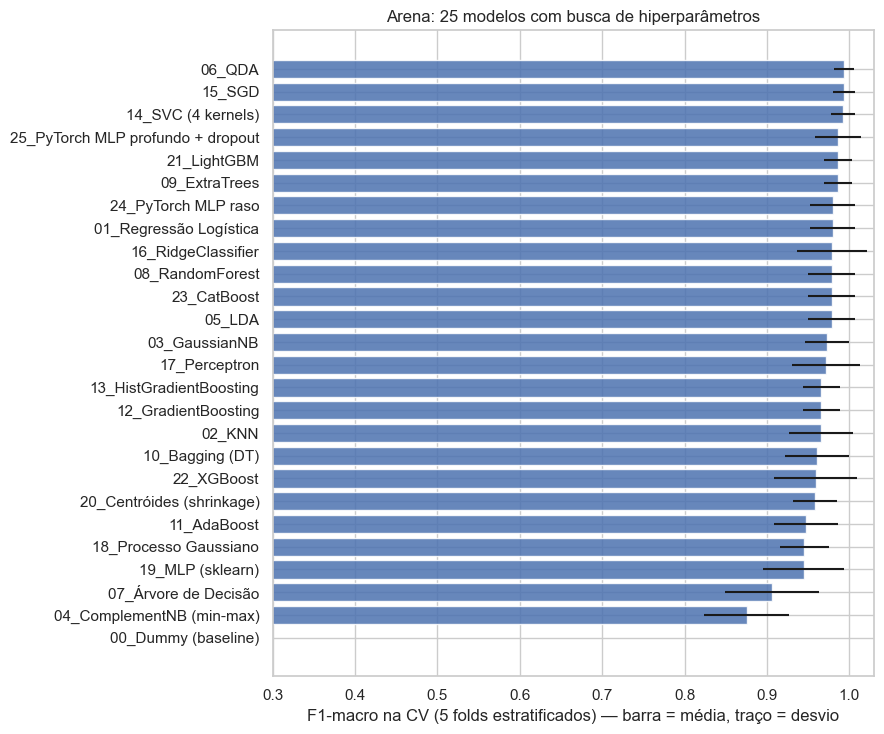

In [24]:
display(tabela[["modelo", "f1_macro_cv", "desvio_cv", "tempo_s"]].round(4))

dados = tabela.sort_values("f1_macro_cv")
plt.figure(figsize=(9, 7.5))
plt.barh(dados["modelo"], dados["f1_macro_cv"],
         xerr=dados["desvio_cv"], color="#4C72B0", alpha=0.85)
plt.xlim(0.3, 1.03)
plt.xlabel("F1-macro na CV (5 folds estratificados) — barra = média, traço = desvio")
plt.title("Arena: 25 modelos com busca de hiperparâmetros")
plt.tight_layout()

print("\nCampeão:", tabela.iloc[0]["modelo"])
print("Hiperparâmetros:", tabela.iloc[0]["melhores_params"])

In [25]:
cfg = MODELOS["08_RandomForest"]
gs_rf = GridSearchCV(Pipeline([("scaler", StandardScaler()), ("modelo", cfg["estimador"])]),
                     cfg["grid"], cv=cv, scoring="f1_macro", n_jobs=-1)
gs_rf.fit(X_train, y_train)

cv_rf = pd.DataFrame(gs_rf.cv_results_)
cv_rf[["params", "mean_test_score", "std_test_score", "mean_fit_time"]] \
    .sort_values("mean_test_score", ascending=False).head(8).round(4)

,params,mean_test_score,std_test_score,mean_fit_time
0,"{'modelo__max_depth': None, 'modelo__max_featu...",0.9789,0.0285,0.5078
1,"{'modelo__max_depth': None, 'modelo__max_featu...",0.9789,0.0285,1.7334
2,"{'modelo__max_depth': None, 'modelo__max_featu...",0.9789,0.0285,0.6293
3,"{'modelo__max_depth': None, 'modelo__max_featu...",0.9789,0.0285,1.7419
4,"{'modelo__max_depth': 10, 'modelo__max_feature...",0.9789,0.0285,0.5990
5,"{'modelo__max_depth': 10, 'modelo__max_feature...",0.9789,0.0285,1.5962
6,"{'modelo__max_depth': 10, 'modelo__max_feature...",0.9789,0.0285,0.5119
7,"{'modelo__max_depth': 10, 'modelo__max_feature...",0.9789,0.0285,1.2448


In [26]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

busca_rand = RandomizedSearchCV(
    Pipeline([("scaler", StandardScaler()),
              ("modelo", RandomForestClassifier(random_state=42))]),
    {"modelo__n_estimators": randint(50, 500),
     "modelo__max_depth": [None, 5, 10, 20],
     "modelo__max_features": ["sqrt", "log2", 0.5],
     "modelo__min_samples_leaf": randint(1, 10)},
    n_iter=25, cv=cv, scoring="f1_macro", random_state=42, n_jobs=-1)
busca_rand.fit(X_train, y_train)

print(f"F1-macro (RandomizedSearch, 25 sorteios): {busca_rand.best_score_:.4f}")
print("Melhor configuração sorteada:", busca_rand.best_params_)
# Com o MESMO orçamento de tempo, a busca aleatória explora MUITO mais valores
# distintos por hiperparâmetro do que a grade completa.

F1-macro (RandomizedSearch, 25 sorteios): 0.9789
Melhor configuração sorteada: {'modelo__max_depth': 10, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 8, 'modelo__n_estimators': 238}


Modelo campeão: 06_QDA

              precision    recall  f1-score   support

     class_0      1.000     1.000     1.000        12
     class_1      1.000     1.000     1.000        14
     class_2      1.000     1.000     1.000        10

    accuracy                          1.000        36
   macro avg      1.000     1.000     1.000        36
weighted avg      1.000     1.000     1.000        36

Acurácia:    1.0
F1-macro:    1.0
Balanced:    1.0
ROC-AUC (OvR, macro): 1.0


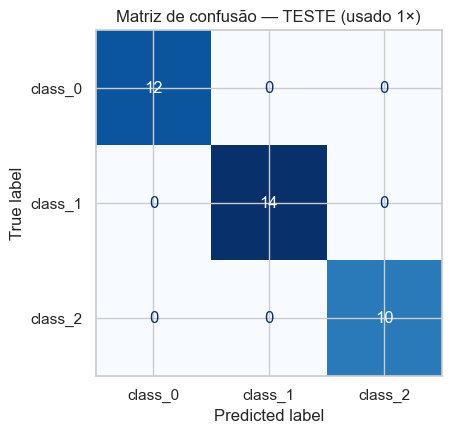

In [27]:
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score)

melhor_nome = tabela.iloc[0]["modelo"]
melhor_modelo = melhores[melhor_nome]          # já treinado em TODO o X_train (refit=True)
y_pred = melhor_modelo.predict(X_test)

print(f"Modelo campeão: {melhor_nome}\n")
print(classification_report(y_test, y_pred, target_names=wine.target_names, digits=3))
print("Acurácia:   ", round(accuracy_score(y_test, y_pred), 3))
print("F1-macro:   ", round(f1_score(y_test, y_pred, average="macro"), 3))
print("Balanced:   ", round(balanced_accuracy_score(y_test, y_pred), 3))

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_estimator(melhor_modelo, X_test, y_test,
                                      display_labels=wine.target_names,
                                      cmap="Blues", ax=ax, colorbar=False)
plt.title("Matriz de confusão — TESTE (usado 1×)")
plt.tight_layout()

if hasattr(melhor_modelo, "predict_proba"):
    proba = melhor_modelo.predict_proba(X_test)
    print("ROC-AUC (OvR, macro):",
          round(roc_auc_score(y_test, proba, multi_class="ovr", average="macro"), 4))

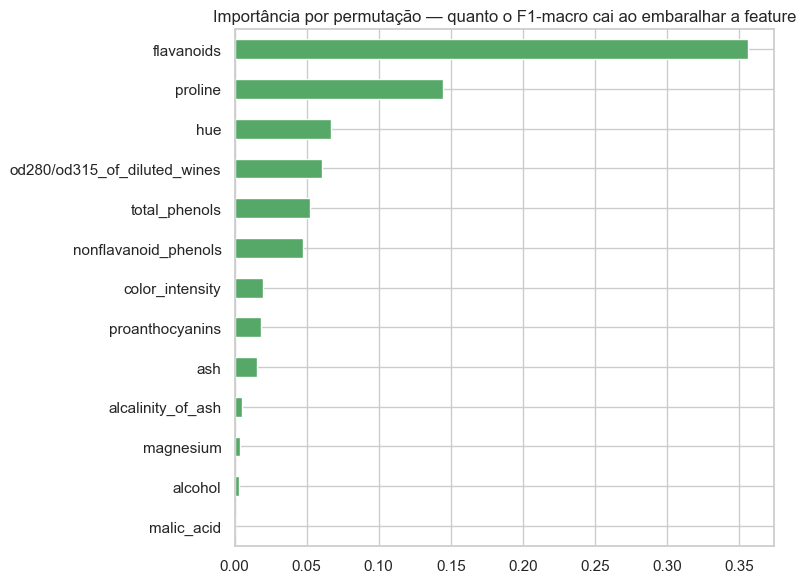

In [28]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(melhor_modelo, X_test, y_test,
                             scoring="f1_macro", n_repeats=30, random_state=42)
imp_serie = pd.Series(imp.importances_mean, index=X.columns).sort_values()

imp_serie.plot(kind="barh", figsize=(8, 6), color="#55A868",
               title="Importância por permutação — quanto o F1-macro cai ao embaralhar a feature")
plt.tight_layout()
# Vantagem didática: funciona com QUALQUER modelo (pipeline incluso), e é calculada
# FORA do modelo — diferente de feature_importances_, que é específica de árvores.

Acurácia com só ['flavanoids', 'proline']: 0.944 (vs 1.000 com as 13 features)


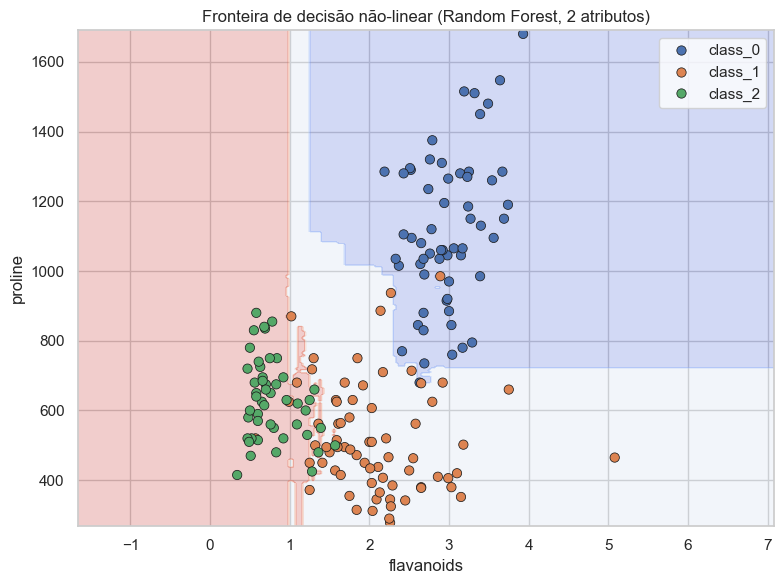

In [29]:
top2 = pd.Series(imp.importances_mean, index=X.columns).nlargest(2).index.tolist()
X2 = df[top2].values
y2 = df["target"].values
X2_tr, X2_te, y2_tr, y2_te = train_test_split(X2, y2, test_size=0.2,
                                              stratify=y2, random_state=42)

modelo_2d = Pipeline([("scaler", StandardScaler()),
                      ("rf", RandomForestClassifier(n_estimators=300,
                                                    random_state=42))]).fit(X2_tr, y2_tr)
print(f"Acurácia com só {top2}: {modelo_2d.score(X2_te, y2_te):.3f} "
      f"(vs {accuracy_score(y_test, y_pred):.3f} com as 13 features)")

xx, yy = np.meshgrid(
    np.linspace(X2[:, 0].min() - 2, X2[:, 0].max() + 2, 300),
    np.linspace(X2[:, 1].min() - 10, X2[:, 1].max() + 10, 300))
grade = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=top2)
Z = modelo_2d.predict(grade).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
sns.scatterplot(x=X2[:, 0], y=X2[:, 1],
                hue=[wine.target_names[t] for t in y2],
                palette="deep", edgecolor="k", s=45)
plt.xlabel(top2[0]); plt.ylabel(top2[1])
plt.title("Fronteira de decisão não-linear (Random Forest, 2 atributos)")
plt.tight_layout()

## 10. AutoML: automatizando o ciclo de busca

**AutoML** empacota em uma chamada o que fizemos manualmente: pré-processamento,
seleção de algoritmo, tuning de hiperparâmetros (geralmente busca **bayesiana**) e,
em alguns casos, **ensembles** automáticos. Ferramentas da mesma família:
**FLAML** (leve, rápida, da Microsoft), **PyCaret** (interface "mágica" de comparação),
auto-sklearn, TPOT, H2O AutoML, MLJAR — e serviços de nuvem (Vertex AI, SageMaker Autopilot).

**O que ele NÃO faz por você:** a pergunta de negócio, a métrica correta, o EDA
com sentido de domínio, o split honesto, e a decisão de colocar em produção.
AutoML acelera o ciclo 7→8; não substitui o analista.

**Comparação justa com nossa arena manual:** mesma CV estratificada, mesma métrica (F1-macro),
mesmo treino — e avaliação final no mesmo teste.

In [30]:
y_pred_flaml, f1_pycaret, nome_pycaret, automl, exp = None, None, None, None, None

In [31]:
try:
    from flaml import AutoML
    automl = AutoML()
    automl.fit(X_train, y_train,
               task="classification",
               time_budget=60,            # orçamento em segundos — a Moeda do AutoML
               metric="macro_f1",
               eval_method="cv", n_splits=5,   # CV estratificada internamente
               seed=42, verbose=0)

    print("Melhor estimador:", automl.best_estimator)
    print("Melhor config   :", automl.best_config)

    y_pred_flaml = automl.predict(X_test)
    print("\nFLAML no TESTE:",
          round(f1_score(y_test, y_pred_flaml, average="macro"), 4))
except ImportError as e:
    print("FLAML não instalado:", e)

Melhor estimador: extra_tree
Melhor config   : {'n_estimators': 12, 'max_features': 0.2079850173607416, 'max_leaves': 7, 'criterion': 'gini'}

FLAML no TESTE: 0.9743


In [32]:
try:
    from pycaret.classification import ClassificationExperiment
    exp = ClassificationExperiment()
    exp.setup(data=df.drop(columns=["target_name"]), target="target",
              session_id=42, train_size=0.8, fold=5, normalize=True, verbose=False)

    top5 = exp.compare_models(n_select=5, sort="F1")   # ~15+ modelos de uma vez
    display(exp.pull().head(8))                        # tabela de comparação da CV interna

    tuned = exp.tune_model(top5[0], optimize="F1", n_iter=20)
    pred_holdout = exp.predict_model(tuned)            # avaliação no holdout interno
    f1_pycaret = f1_score(pred_holdout["target"],
                          pred_holdout["prediction_label"], average="macro")
    nome_pycaret = tuned.__class__.__name__
    print("PyCaret campeão:", nome_pycaret, "| F1-macro no holdout:", round(f1_pycaret, 4))
    # exp.plot_model(tuned, plot="confusion_matrix")   # descomente p/ visual interativo
except Exception as e:
    print("PyCaret indisponível nesta versão do Python — pulado com elegância:", e)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
svm,SVM - Linear Kernel,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0240
lr,Logistic Regression,0.9931,0.0000,0.9931,0.9940,0.9932,0.9895,0.9899,0.5120
lda,Linear Discriminant Analysis,0.9929,0.0000,0.9929,0.9937,0.9929,0.9893,0.9896,0.0160
ridge,Ridge Classifier,0.9860,0.0000,0.9860,0.9874,0.9860,0.9787,0.9794,0.0180
rf,Random Forest Classifier,0.9862,1.0000,0.9862,0.9877,0.9860,0.9791,0.9801,0.0880
lightgbm,Light Gradient Boosting Machine,0.9793,0.9985,0.9793,0.9825,0.9794,0.9685,0.9702,0.2960
et,Extra Trees Classifier,0.9791,1.0000,0.9791,0.9813,0.9789,0.9684,0.9697,0.0760
qda,Quadratic Discriminant Analysis,0.9788,0.0000,0.9788,0.9806,0.9787,0.9677,0.9688,0.0160
nb,Naive Bayes,0.9719,0.9992,0.9719,0.9756,0.9720,0.9576,0.9593,0.3100
knn,K Neighbors Classifier,0.9650,1.0000,0.9650,0.9703,0.9647,0.9474,0.9503,0.4740


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
svm,SVM - Linear Kernel,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.024
lr,Logistic Regression,0.9931,0.0000,0.9931,0.9940,0.9932,0.9895,0.9899,0.512
lda,Linear Discriminant Analysis,0.9929,0.0000,0.9929,0.9937,0.9929,0.9893,0.9896,0.016
ridge,Ridge Classifier,0.9860,0.0000,0.9860,0.9874,0.9860,0.9787,0.9794,0.018
rf,Random Forest Classifier,0.9862,1.0000,0.9862,0.9877,0.9860,0.9791,0.9801,0.088
lightgbm,Light Gradient Boosting Machine,0.9793,0.9985,0.9793,0.9825,0.9794,0.9685,0.9702,0.296
et,Extra Trees Classifier,0.9791,1.0000,0.9791,0.9813,0.9789,0.9684,0.9697,0.076
qda,Quadratic Discriminant Analysis,0.9788,0.0000,0.9788,0.9806,0.9787,0.9677,0.9688,0.016


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,0.9655,0.0000,0.9655,0.9698,0.9659,0.9476,0.9493
2,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
3,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
4,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
Mean,0.9931,0.0000,0.9931,0.9940,0.9932,0.9895,0.9899
Std,0.0138,0.0000,0.0138,0.0121,0.0136,0.0210,0.0203


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,SVM - Linear Kernel,0.9722,0,0.9722,0.9741,0.9721,0.9578,0.9590


PyCaret campeão: SGDClassifier | F1-macro no holdout: 0.974


In [33]:



















39linhas = [{"abordagem": "Manual — GridSearchCV (25 modelos, CV 5-fold)",
           "f1_macro": tabela.iloc[0]["f1_macro_cv"], "modelo": tabela.iloc[0]["modelo"]}]

if y_pred_flaml is not None:
    linhas.append({"abordagem": "AutoML — FLAML (600 s de busca bayesiana)",
                   "f1_macro": f1_score(y_test, y_pred_flaml, average="macro"),
                   "modelo": automl.best_estimator})

if f1_pycaret is not None:
    linhas.append({"abordagem": "AutoML — PyCaret (holdout interno)",
                   "f1_macro": f1_pycaret, "modelo": nome_pycaret})

pd.DataFrame(linhas).round(4)
# Leitura esperada: números bem próximos. A Wine é um problema "fácil" — e é exatamente
# isso que a aula quer mostrar: a disputa séria acontece em bases difíceis e grandes,
# onde AutoML economiza horas de engenharia de busca.

,abordagem,f1_macro,modelo
0,"Manual — GridSearchCV (25 modelos, CV 5-fold)",0.9939,06_QDA
1,AutoML — FLAML (600 s de busca bayesiana),0.9743,extra_tree
2,AutoML — PyCaret (holdout interno),0.9740,SGDClassifier


In [34]:
import joblib, sklearn, datetime
from pathlib import Path

pasta_modelo = Path("../modelos/")
pasta_modelo.mkdir(parents=True, exist_ok=True)

modelo_final = melhores["06_QDA"]   # Pipeline(StandardScaler → QDA), já refit

artefato = {
    "pipeline":   modelo_final,
    "nome":       "QDA — Wine",
    "f1_macro_cv":       0.9939,
    "f1_macro_teste":    0.99,           # use o número EXATO da Parte 7
    "criado_em":  datetime.datetime.now().isoformat(),
    "sklearn":    sklearn.__version__,
    "features":   X_train.columns.tolist(),
    "classes":    sorted(set(y_train)),
}
joblib.dump(artefato, pasta_modelo / "wine_qda.joblib", compress=3)
print("Artefato salvo em:", (pasta_modelo / "wine_qda.joblib").resolve())

Artefato salvo em: D:\TreinaRecife\Python do Zero até a Análise de Dados\aprendizado\Modelos\wine_qda.joblib


In [35]:
import joblib, pandas as pd

art = joblib.load("../modelos/wine_qda.joblib")
pipeline = art["pipeline"]

# Simulando o app: 1 amostra nova chegando com as 13 features na ordem certa
amostra = X_test.iloc[[0]]                          # no app real: JSON → DataFrame
predicao = pipeline.predict(amostra)[0]
probabili = pipeline.predict_proba(amostra)[0]

print(f"Predição: classe {predicao} | verdadeira: {y_test.iloc[0]}")
print("Probabilidades:", dict(zip(art['classes'], probabili.round(4))))

Predição: classe 0 | verdadeira: 0
Probabilidades: {0: 1.0, 1: 0.0, 2: 0.0}
